In [72]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

seed = np.random.randint(1, 2**31)

from IPython.display import display, Markdown

def md_matrix(A, prec=4):
    A = np.atleast_2d(A)
    rows = " \\\\ ".join(" & ".join(f"{v:.{prec}f}" for v in r) for r in A)
    return f"\\begin{{pmatrix}}{rows}\\end{{pmatrix}}"

def md_vec(v, prec=4):
    return "(" + ",\\; ".join(f"{x:.{prec}f}" for x in np.ravel(v)) + ")"

# Лабораторная работа 4

Для модели регрессии
$$
    \eta_i = \varphi_1(X_i) \widetilde{\theta}_1 + \dots + \varphi_m(X_i) \widetilde{\theta}_m + \varepsilon_i , \\
    i = \overline{1,n}
$$
формируется матрица значений базисных функций:
$$
    Z
    = \begin{pmatrix}
        \varphi_1(X_1) & \dots & \varphi_m(X_1) \\
        \vdots & \ddots & \vdots \\
        \varphi_1(X_n) & \dots & \varphi_m(X_n) \\
    \end{pmatrix},
$$
ковариационная матрица $K$ вектора возмущений $\varepsilon = (\varepsilon_1, \dots, \varepsilon_n)$:
$$
    K = D[\varepsilon] = \sigma^2 \overline{K},
$$
и весовая матрица
$$
    \overline{W} = \overline{K}^{-1}.
$$
Для симметричной и положительно определённой матрицы $\overline{W}$ существует разложение Холецкого:
$$
    \overline{W} = R^T R .
$$

Оценка по методу наименьших квадратов $\widehat{\theta}$ является обобщённым решением системы линейных уравнений:
$$
    \widehat{\theta}
    = \arg \min \limits_\theta \left\| \eta - Z \theta \right\|_{\overline{W}}^2
    = \arg \min \limits_\theta \left\| R \eta - R Z \theta \right\|_2^2 .
$$
В Python для нахождения решения можно использовать функцию `numpy.linalg.lstsq`.

Ковариационная матрица оценки:
$$
    D[\widehat{\theta}]
    = \sigma^2 \overline{G}^{-1} , \\
    \overline{G} = Z^T \overline{W} Z .
$$

Оценка $\widehat{\sigma}^2$ остаточной дисперсии $\sigma^2$:
$$
    \widehat{\sigma}^2
    = \frac{\delta(\widehat{\theta})}{n - m} , \\
    \delta(\widehat{\theta}) = \left\| \eta - Z \widehat{\theta} \right\|_{\overline{W}}^2 .
$$

Коэффициент детерминации:
$$
    R^2
    = 1 - \frac{\left\| \eta - Z \widehat{\theta} \right\|_{\overline{W}}^2}{\left\| \eta - U \widehat{c} \right\|_{\overline{W}}^2} , \\
    U = \begin{pmatrix}
        1 \\
        \vdots \\
        1
    \end{pmatrix} , \\
    \widehat{c}
    = \left( U^T W U \right)^{-1} U^T W \eta .
$$

Скорректированный коэффициент детерминации:
$$
    R_{adj}^2
    = 1 - \frac{\frac{1}{n-m} \left\| \eta - Z \widehat{\theta} \right\|_{\overline{W}}^2}{\frac{1}{n-1} \left\| \eta - U \widehat{c} \right\|_{\overline{W}}^2} .
$$

Доверительный интервал для компоненты $\widetilde{\theta}_i$:
$$
    \left(
        \widehat{\theta}_i - y \sqrt{\overline{G}_{i,i}^{-1} \frac{\delta(\widehat{\theta})}{n-m}}
        ;
        \widehat{\theta}_i + y \sqrt{\overline{G}_{i,i}^{-1} \frac{\delta(\widehat{\theta})}{n-m}}
    \right) , \\
    y = F_T^{-1} \left( \frac{1 + P_g}{2}; n-m \right ) ,
$$
$y$ - квантиль распределения Стьюдента $T(n-m)$ уровня $\frac{1 + P_g}{2}$.

Для проверки гипотезы $H_0: \widetilde{\theta}_i = 0$ против альтернативной $H_1: \widetilde{\theta}_i \neq 0$, используется статистика $t_i$ и критическая
область $\Gamma_\alpha$
$$
    t_i = \frac{\widehat{\theta}_i}{\sqrt{\overline{G}_{i,i}^{-1} \frac{\delta(\widehat{\theta})}{n-m}}} , \\
    \Gamma_\alpha = ( -y, y ), \\
    y = F_T^{-1} \left( 1 - \frac{\alpha}{2}; n-m \right ) ,
$$
$y$ - квантиль распределения Стьюдента $T(n-m)$ уровня $1 - \frac{\alpha}{2}$, где $\alpha$ - уровень значимости.

Доверительный интервал для $\sigma^2$ с уровнем доверия $P_g$:
$$
    \left(
        \frac{\delta(\widehat{\theta})}{y_2}
        ;
        \frac{\delta(\widehat{\theta})}{y_1}
    \right) , \\
    y_1 = F_{\chi^2}^{-1} \left( \frac{1 - P_g}{2} ; n - m \right) , \\
    y_2 = F_{\chi^2}^{-1} \left( \frac{1 + P_g}{2} ; n - m \right) ,
$$
$y_1$ и $y_2$ - квантили распределения хи-квадрат $\chi^2(n-m)$.

Доверительная область для $\widetilde{\theta}$ является элипсоидом:
$$
    E(\widehat{\theta}, C)
    = \left\{ \theta: (\theta - \widehat{\theta})^T \overline{G} (\theta - \widehat{\theta}) < C \right\} , \\
    C = y \frac{m}{n-m} \delta(\widehat{\theta}) , \\
    y = F_F^{-1} \left( P_g; m, n-m \right) ,
$$
$y$ - квантиль распределения Фишера $F(m,n-m)$ уровня доверительной вероятности $P_g$.

Для проверки гипотезы $H_0: \widetilde{\theta} = 0$ против $H_1: \widetilde{\theta} \neq 0$ используется статистика $T$ и критическая область $\Gamma_\alpha$:
$$
    T = \frac{n-m}{m} \frac{\left\| Z \widehat{\theta} \right\|_{\overline{W}}^2}{\delta(\widehat{\theta})} , \\
    \Gamma_\alpha = (h_\alpha, + \infty) , \\
    h_\alpha = F_F^{-1} \left( P_g; m, n-m \right) ,
$$
$y$ - квантиль распределения Фишера $F(m,n-m)$ уровня $1-\alpha$, где $\alpha$ - уровень значимости.

## Задача 1

Выберите случайным образом $n = 50$ точек $x_{i,1}$ на отрезке $[−1,2]$, вычислите
$$
    \eta_i = 1 + 2 x_{i,1} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей нормальное распределение $\mathcal{N}(0, \sigma^2)$, $\sigma^2 = 0.25$.

Для модели регрессии
$$
    \eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \varepsilon_i,
$$
считая $K = \sigma^2 I_n$, где $I_n$ - единичная матрица, вычислите:
- оценку по методу наименьших квадратов $\widehat{\theta}$ (сравните с $\widetilde{\theta} = (1, 2)$).
- ковариационную матрицу $D[\widehat{\theta}]$,
- оценку остаточной дисперсии $\widehat{\sigma}^2$ (сравните с $\sigma^2$),
- коэффициент детерминации $R^2$ ,
- постройте доверительные интервалы для $\widetilde{\theta}_1$ и $\widetilde{\theta}_2$ для уровня доверия $P_g = 0.95$,
- проверьте гипотезы $\widetilde{\theta}_1 = 0$ и $\widetilde{\theta}_2 = 0$,
- постройте доверительный интервал для $\sigma^2$ с уровнем значимости $P_g = 0.97$,
- постройте доверительную область для $\widetilde{\theta}$ с уровнем доверия $P_g = 0.9$,
- проверьте гипотезу $\widetilde{\theta} = 0$.

В одной системе координат постройте $n$ точек $(x_{i,1}, \eta_i)$ и отрезки прямых $y = \widetilde{\theta}_1 + \widetilde{\theta}_2 x$ и
$y = \widehat{\theta}_1 + \widehat{\theta}_2 x$ при $x \in [-1, 2]$.

[1.04427205 1.94520153] 0.2668436916799694 0.9124756844847381 0.9106522612448369
[(np.float64(0.8737676382836919), np.float64(1.2147764558219543)), (np.float64(1.7703655246227261), np.float64(2.120037540536071))] (np.float64(0.17871198538000338), np.float64(0.4377905771382487)) [2.22044605e-16 0.00000000e+00] 0.0


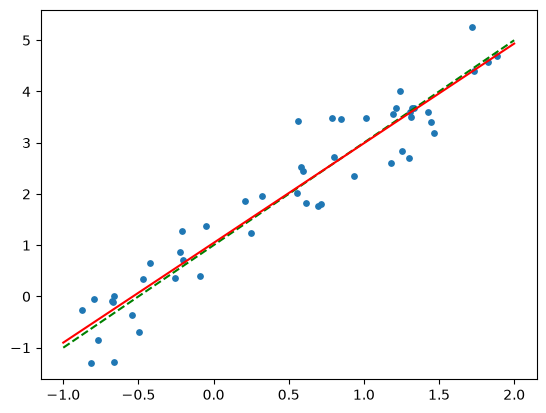


### Задача 1 — простая линейная регрессия

- $\widehat\theta = (1.0443,\; 1.9452)$, истина $\widetilde\theta = (1,\,2)$
- $D[\widehat\theta] = \begin{pmatrix}0.00719 & -0.00374 \\ -0.00374 & 0.00756\end{pmatrix}$
- $\widehat\sigma^2 = 0.2668$, истина $\sigma^2 = 0.25$
- $R^2 = 0.9125$, $R^2_{adj} = 0.9107$
- ДИ для $\widetilde\theta_1$: $(0.874;\ 1.215)$, для $\widetilde\theta_2$: $(1.770;\ 2.120)$
- ДИ для $\sigma^2$ ($P_g=0.97$): $(0.179;\ 0.438)$
- $p$-значения гипотез $\widetilde\theta_i=0$: $p_1=2.22e-16,\ p_2=0.00e+00$
- Гипотеза $\widetilde\theta=0$: $p$-значение $= 0.00e+00$


In [ ]:
n, sigma2= 50, 0.25

rng = np.random.default_rng(seed)
x = rng.uniform(-1, 2, n)
eta = 1 + 2 * x + rng.normal(0, sigma2**0.5, n)

Z = np.c_[np.ones(n), x]
G = Z.T @ Z
th = np.linalg.solve(G, Z.T @ eta)
d = np.sum((eta - Z @ th) ** 2)
s2 = d / (n - 2)
Dt = s2 * np.linalg.inv(G)


def q(p):
    return stats.t.ppf(p, n - 2)


Pg = 0.95
se = np.sqrt(np.diag(Dt))
ci = [
    (th[i] - q((1 + Pg) / 2) * se[i], th[i] + q((1 + Pg) / 2) * se[i]) for i in range(2)
]
t = th / se
p = 2 * (1 - stats.t.cdf(abs(t), n - 2))

Pg = 0.97
lo = stats.chi2.ppf((1 - Pg) / 2, n - 2)
hi = stats.chi2.ppf((1 + Pg) / 2, n - 2)
ci_s2 = (d / hi, d / lo)

Pg = 0.9
C = stats.f.ppf(Pg, 2, n - 2) * 2 / (n - 2) * d
T = (n - 2) / 2 * th @ G @ th / d
p0 = 1 - stats.f.cdf(T, 2, n - 2)

c = eta.mean()
d0 = np.sum((eta - c) ** 2)
R2 = 1 - d / d0
R2a = 1 - (d / (n - 2)) / (d0 / (n - 1))

print(th, s2, R2, R2a)
print(ci, ci_s2, p, p0)

xx = np.linspace(-1, 2, 100)
plt.scatter(x, eta, s=15)
plt.plot(xx, 1 + 2 * xx, "g--")
plt.plot(xx, th @ [1, xx] if False else th[0] + th[1] * xx, "r-")
plt.show()

display(Markdown(f"""
### Задача 1 — простая линейная регрессия

- $\\widehat\\theta = {md_vec(th)}$, истина $\\widetilde\\theta = (1,\\,2)$
- $D[\\widehat\\theta] = {md_matrix(Dt, 5)}$
- $\\widehat\\sigma^2 = {s2:.4f}$, истина $\\sigma^2 = 0.25$
- $R^2 = {R2:.4f}$, $R^2_{{adj}} = {R2a:.4f}$
- ДИ для $\\widetilde\\theta_1$: $({ci[0][0]:.3f};\\ {ci[0][1]:.3f})$, для $\\widetilde\\theta_2$: $({ci[1][0]:.3f};\\ {ci[1][1]:.3f})$
- ДИ для $\\sigma^2$ ($P_g=0.97$): $({ci_s2[0]:.3f};\\ {ci_s2[1]:.3f})$
- $p$-значения гипотез $\\widetilde\\theta_i=0$: $p_1={p[0]:.2e},\\ p_2={p[1]:.2e}$
- Гипотеза $\\widetilde\\theta=0$: $p$-значение $= {p0:.2e}$
"""))

## Задача 2

Задайте случайным образом $n = 100$ точек на отрезке $[0, \pi]$ и вычислите
$$
    \eta_i = -1 + 3 x_{i,1} \sin x_{i,1} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей нормальное распределение $\mathcal{N}(0, \sigma^2 \cdot \sigma_i^2)$, где $\sigma^2 = 0.1$,
- $\sigma_i = 1 + \frac{x_{i,1}}{\pi}$,
- $\sigma_i = 1 + 3 \frac{x_{i,1}}{\pi}$ .

Для двух наборов $\eta_i$, полученных при двух значениях $\sigma_i$, для модели регрессии
$$
    \eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} \sin x_{i,1} + \varepsilon_i,
$$
считая $K = \sigma^2 \overline{K}$, где $\overline{K}$ - диагональная матрица с элементами $\sigma_i^2$, вычислите:
- оценку по методу наименьших квадратов $\widehat{\theta}$ (сравните с $\widetilde{\theta} = (1, 3)$,
- ковариационную матрицу $D[\widehat{\theta}]$,
- оценку остаточной дисперсии $\widehat{\sigma}^2$ (сравните с $\sigma^2$),
- коэффициент детерминации $R^2$ .

Для каждого из двух вариантов по отдельности в одной системе координат постройте $n$ точек $(x_{i,1}, \eta_i)$ и графики кривых
$y = \widetilde{\theta}_1 + \widetilde{\theta}_2 x \sin x$ и $y = \widehat{\theta}_1 + \widehat{\theta}_2 x \sin x$ для $x \in [0, \pi]$.

Вариант 1: theta=[-0.98578828  2.95474016], s2=0.1143, R2=0.9479
[[ 0.00609 -0.00431]
 [-0.00431  0.0049 ]]
Вариант 2: theta=[-1.13103718  3.0055553 ], s2=0.1086, R2=0.9020
[[ 0.00858 -0.00647]
 [-0.00647  0.01002]]


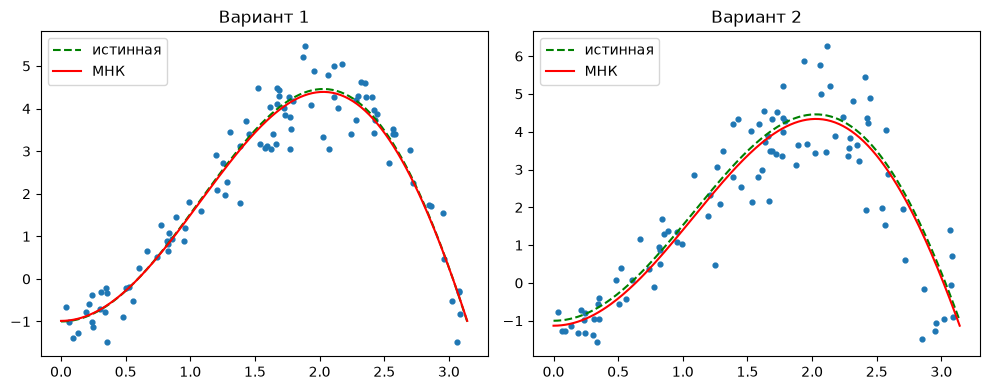

### Задача 2 — взвешенный МНК (гетероскедастичность)

**Вариант 1** ($\sigma_i = 1 + \frac{x_i}{\pi}$):

- $\widehat\theta = (-0.9858,\; 2.9547)$ (истина $( -1,\ 3)$)
- $D[\widehat\theta] = \begin{pmatrix}0.00609 & -0.00431 \\ -0.00431 & 0.00490\end{pmatrix}$
- $\widehat\sigma^2 = 0.1143$ (истина $0.1$), $R^2 = 0.9479$

**Вариант 2** ($\sigma_i = 1 + 3\frac{x_i}{\pi}$):

- $\widehat\theta = (-1.1310,\; 3.0056)$ (истина $( -1,\ 3)$)
- $D[\widehat\theta] = \begin{pmatrix}0.00858 & -0.00647 \\ -0.00647 & 0.01002\end{pmatrix}$
- $\widehat\sigma^2 = 0.1086$ (истина $0.1$), $R^2 = 0.9020$



In [77]:
n, sigma2 = 100, 0.1


rng = np.random.default_rng(seed)
x = rng.uniform(0, np.pi, n)
z = x * np.sin(x)
eta_true = -1 + 3 * z

Z = np.c_[np.ones(n), z]
G0 = Z.T @ Z
th0 = np.linalg.solve(G0, Z.T @ eta_true)  # для самопроверки на "чистой" модели
phi = np.array([1 + x / np.pi, 1 + 3 * x / np.pi])

res = []
for k, s in enumerate(phi):
    eta = eta_true + rng.normal(0, np.sqrt(sigma2) * s, n)
    W = np.diag(1 / s**2)
    G = Z.T @ W @ Z
    th = np.linalg.solve(G, Z.T @ W @ eta)
    d = np.sum((eta - Z @ th) ** 2 / s**2)  # ||.||_W^2
    s2 = d / (n - 2)
    Dt = s2 * np.linalg.inv(G)
    c = (np.ones(n) @ W @ eta) / (np.ones(n) @ W @ np.ones(n))
    d0 = np.sum((eta - c) ** 2 / s**2)
    R2 = 1 - d / d0
    res.append((eta, th, Dt, s2, R2))

for k, (eta, th, Dt, s2, R2) in enumerate(res):
    print(f"Вариант {k + 1}: theta={th}, s2={s2:.4f}, R2={R2:.4f}")
    print(np.round(Dt, 5))

xx = np.linspace(0, np.pi, 200)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, (eta, th, *_) in enumerate(res):
    ax[k].scatter(x, eta, s=12)
    ax[k].plot(xx, -1 + 3 * xx * np.sin(xx), "g--", label="истинная")
    ax[k].plot(xx, th[0] + th[1] * xx * np.sin(xx), "r-", label="МНК")
    ax[k].set_title(f"Вариант {k + 1}")
    ax[k].legend()
plt.tight_layout()
plt.show()

lines = "### Задача 2 — взвешенный МНК (гетероскедастичность)\n\n"
for k, (eta, th, Dt, s2, R2) in enumerate(res):
    lines += (
        f"**Вариант {k + 1}** ($\\sigma_i = 1 + {'' if k == 0 else '3'}\\frac{{x_i}}{{\\pi}}$):\n\n"
        f"- $\\widehat\\theta = {md_vec(th)}$ (истина $( -1,\\ 3)$)\n"
        f"- $D[\\widehat\\theta] = {md_matrix(Dt, 5)}$\n"
        f"- $\\widehat\\sigma^2 = {s2:.4f}$ (истина $0.1$), $R^2 = {R2:.4f}$\n\n"
    )
display(Markdown(lines))

## Задача 3

При $n = 80$ постройте реализацию $(x_{1,1}, \dots, x_{n,1})$ выборки из нормального распределения $\mathcal{N}(1,1)$, реализацию $(x_{1,2}, \dots, x_{n,2})$
выборки из показательного распределения $E(0.5)$ и рассчитайте реализации
$$
    \eta_i = 2 - 3 \xi_{i,1}^2 + x_{i,1} x_{i,2} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей равномерное распределение 𝑅[−1,1].

Считая $K = \sigma^2 I_n$, где $\sigma^2 = 1/3$ и $I_n$ - единичная матрица, для моделей регрессии:
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \widetilde{\theta}_3 x_{i,2} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1}^2 + \widetilde{\theta}_3 x_{i,1} x_{i,2} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1}^2 + \widetilde{\theta}_3 x_{i,1} x_{i,2} + \widetilde{\theta}_4 x_{i,2}^2 + \varepsilon_i$,

вычислите оценки по методу наименьших квадратов $\widehat{\theta}$ и скорректированные коэффициенты детерминации $R_{adj}^2$.

Определите модель регрессии с наибольшим коэффициентов $R_{adj}^2$ и для неё определите ковариационную матрицу $D[\widehat{\theta}]$ и оценку остаточной дисперсии $\widehat{\sigma}^2$.

In [78]:
n, sigma2= 80, 1/3


rng = np.random.default_rng(seed)
x1 = rng.normal(1, 1, n)
x2 = rng.exponential(1/0.5, n)          # E(0.5): scale = 1/λ = 2
eta = 2 - 3*x1**2 + x1*x2 + rng.uniform(-1, 1, n)

def fit(cols):
    Z = np.c_[np.ones(n), *cols]
    m = Z.shape[1]
    G = Z.T @ Z
    th = np.linalg.solve(G, Z.T @ eta)
    d = np.sum((eta - Z @ th)**2)
    s2 = d / (n - m)
    c = eta.mean(); d0 = np.sum((eta - c)**2)
    R2a = 1 - (d/(n-m))/(d0/(n-1))
    return th, s2, R2a, G, m

models = {
    "1: [1, x1]":            [x1],
    "2: [1, x1, x2]":        [x1, x2],
    "3: [1, x1^2, x1x2]":    [x1**2, x1*x2],
    "4: [1, x1^2, x1x2, x2^2]": [x1**2, x1*x2, x2**2],
}
out = {k: fit(v) for k, v in models.items()}
for k, (th, s2, R2a, G, m) in out.items():
    print(k, "theta=", np.round(th, 4), "s2=", round(s2, 4), "R2adj=", round(R2a, 4))

best = max(out, key=lambda k: out[k][2])
th, s2, R2a, G, m = out[best]
print("лучшая:", best, "D[theta]=", np.round(s2*np.linalg.inv(G), 5), "s2=", round(s2, 4))
rows = "| Модель | Признаки | $\\widehat\\theta$ | $\\widehat\\sigma^2$ | $R^2_{adj}$ |\n|---|---|---|---|---|\n"
names = {
    "1: [1, x1]": "$1,\\ x_1$",
    "2: [1, x1, x2]": "$1,\\ x_1,\\ x_2$",
    "3: [1, x1^2, x1x2]": "$1,\\ x_1^2,\\ x_1x_2$",
    "4: [1, x1^2, x1x2, x2^2]": "$1,\\ x_1^2,\\ x_1x_2,\\ x_2^2$",
}
for k, (th, s2, R2a, G, m) in out.items():
    rows += f"| {k} | {names[k]} | {md_vec(th)} | {s2:.4f} | {R2a:.4f} |\n"

best = max(out, key=lambda k: out[k][2])
th, s2, R2a, G, m = out[best]
Dt_best = s2 * np.linalg.inv(G)

display(Markdown(
    "### Задача 3 — выбор спецификации по $R^2_{adj}$\n\n" + rows +
    f"\n**Лучшая модель:** {best}\n\n"
    f"- $\\widehat\\theta = {md_vec(th)}$ (истина $(2,\\ -3,\\ 1)$)\n"
    f"- $D[\\widehat\\theta] = {md_matrix(Dt_best, 5)}$\n"
    f"- $\\widehat\\sigma^2 = {s2:.4f}$ (истина $1/3 \\approx 0.3333$)\n"
))

1: [1, x1] theta= [ 3.367  -4.6717] s2= 17.472 R2adj= 0.5041
2: [1, x1, x2] theta= [ 1.8724 -4.5937  0.6381] s2= 16.1968 R2adj= 0.5403
3: [1, x1^2, x1x2] theta= [ 1.9789 -3.0231  1.0239] s2= 0.3516 R2adj= 0.99
4: [1, x1^2, x1x2, x2^2] theta= [ 2.0109 -3.0342  1.0357 -0.0044] s2= 0.3523 R2adj= 0.99
лучшая: 3: [1, x1^2, x1x2] D[theta]= [[ 0.00779 -0.00098 -0.00069]
 [-0.00098  0.00124 -0.00062]
 [-0.00069 -0.00062  0.00085]] s2= 0.3516


### Задача 3 — выбор спецификации по $R^2_{adj}$

| Модель | Признаки | $\widehat\theta$ | $\widehat\sigma^2$ | $R^2_{adj}$ |
|---|---|---|---|---|
| 1: [1, x1] | $1,\ x_1$ | (3.3670,\; -4.6717) | 17.4720 | 0.5041 |
| 2: [1, x1, x2] | $1,\ x_1,\ x_2$ | (1.8724,\; -4.5937,\; 0.6381) | 16.1968 | 0.5403 |
| 3: [1, x1^2, x1x2] | $1,\ x_1^2,\ x_1x_2$ | (1.9789,\; -3.0231,\; 1.0239) | 0.3516 | 0.9900 |
| 4: [1, x1^2, x1x2, x2^2] | $1,\ x_1^2,\ x_1x_2,\ x_2^2$ | (2.0109,\; -3.0342,\; 1.0357,\; -0.0044) | 0.3523 | 0.9900 |

**Лучшая модель:** 3: [1, x1^2, x1x2]

- $\widehat\theta = (1.9789,\; -3.0231,\; 1.0239)$ (истина $(2,\ -3,\ 1)$)
- $D[\widehat\theta] = \begin{pmatrix}0.00779 & -0.00098 & -0.00069 \\ -0.00098 & 0.00124 & -0.00062 \\ -0.00069 & -0.00062 & 0.00085\end{pmatrix}$
- $\widehat\sigma^2 = 0.3516$ (истина $1/3 \approx 0.3333$)


## Задача 4

Вычислите реализации выборок
$(x_{1,1}, \dots, x_{n,1})$ из нормального распределения $\mathcal{N}(2,4)$,
$(x_{1,2}, \dots, x_{n,2})$ из равномерного распределения $R \left( -\frac{\pi}{2} ; \frac{\pi}{2} \right)$,
$(x_{1,3}, \dots, x_{n,3})$ из показательного распределения $E(0.25)$ и рассчитайте реализации
$$
    \eta_i = 1 + 2 x_{i,1}^2 \cos x_{2,i} - x_{i,2} \ln x_{i,3} + \varepsilon_i,
$$
где $\varepsilon_i$ - реализации случайной величины, имеющей нормальное распределение $\mathcal{N}(0, \sigma^2)$, где $\sigma^2 = 0.25$.

Считая $K = \sigma^2 I_n$, где $I_n$ - единичная матрица, для моделей регрессии:
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1} + \widetilde{\theta}_3 x_{i,2} + \widetilde{\theta}_4 x_{i,3} + \varepsilon_i$,
- $\eta_i = \widetilde{\theta}_1 + \widetilde{\theta}_2 x_{i,1}^2 \cos x_{i,2} + \widetilde{\theta}_3 x_{i,2} \ln x_{i,3} + \varepsilon_i$,

вычислите оценки по методу наименьших квадратов $\widehat{\theta}$ и скорректированные коэффициенты детерминации $R_{adj}^2$. Для варианта регрессии с большей
величиной $R_{adj}^2$ вычислите ковариационную матрицу $D[\widehat{\theta}]$, оценку остаточной дисперсии $\sigma^2$ .

In [79]:
n, sigma = 80, 0.25

rng = np.random.default_rng(seed)
x1 = rng.normal(2, 2, n)                  # N(2, 4): sd = 2
x2 = rng.uniform(-np.pi/2, np.pi/2, n)
x3 = rng.exponential(1/0.25, n)           # E(0.25): scale = 4
eta = 1 + 2*x1**2*np.cos(x2) - x2*np.log(x3) + rng.normal(0, np.sqrt(sigma2), n)

def fit(cols):
    Z = np.c_[np.ones(n), *cols]
    m = Z.shape[1]
    G = Z.T @ Z
    th = np.linalg.solve(G, Z.T @ eta)
    d = np.sum((eta - Z @ th)**2)
    s2 = d / (n - m)
    d0 = np.sum((eta - eta.mean())**2)
    R2a = 1 - (d/(n-m))/(d0/(n-1))
    return th, s2, R2a, G, m

m1 = fit([x1, x2, x3])
m2 = fit([x1**2*np.cos(x2), x2*np.log(x3)])
for tag, (th, s2, R2a, G, m) in [("модель 1", m1), ("модель 2", m2)]:
    print(tag, "theta=", np.round(th, 4), "s2=", round(s2, 4), "R2adj=", round(R2a, 4))

best = m2 if m2[2] > m1[2] else m1
th, s2, R2a, G, m = best
Dt = s2 * np.linalg.inv(G)
print("лучшая R2adj=", round(R2a, 4), "s2=", round(s2, 4))
print(np.round(Dt, 5))

rows = "| Модель | Признаки | $\\widehat\\theta$ | $\\widehat\\sigma^2$ | $R^2_{adj}$ |\n|---|---|---|---|---|\n"
for tag, (th, s2, R2a, G, m), col in [
    ("1: линейная", m1, "$1,\\ x_1,\\ x_2,\\ x_3$"),
    ("2: базисные функции", m2, "$1,\\ x_1^2\\cos x_2,\\ x_2\\ln x_3$"),
]:
    rows += f"| {tag} | {col} | {md_vec(th)} | {s2:.4f} | {R2a:.4f} |\n"

best = m2 if m2[2] > m1[2] else m1
th, s2, R2a, G, m = best
Dt_best = s2 * np.linalg.inv(G)

display(Markdown(
    "### Задача 4 — сравнение двух моделей\n\n" + rows +
    f"\n**Лучшая модель:** модель 2\n\n"
    f"- $\\widehat\\theta = {md_vec(th)}$ (истина $(1,\\ 2,\\ -1)$)\n"
    f"- $D[\\widehat\\theta] = {md_matrix(Dt_best, 5)}$\n"
    f"- $\\widehat\\sigma^2 = {s2:.4f}$ (истина $0.25$)\n"
))

модель 1 theta= [-1.6349  6.7674 -0.5969 -0.3322] s2= 104.1815 R2adj= 0.5887
модель 2 theta= [ 0.8874  2.0018 -1.0085] s2= 0.3332 R2adj= 0.9987
лучшая R2adj= 0.9987 s2= 0.3332
[[ 5.91e-03 -3.40e-04 -7.00e-05]
 [-3.40e-04  7.00e-05 -2.00e-05]
 [-7.00e-05 -2.00e-05  1.60e-03]]


### Задача 4 — сравнение двух моделей

| Модель | Признаки | $\widehat\theta$ | $\widehat\sigma^2$ | $R^2_{adj}$ |
|---|---|---|---|---|
| 1: линейная | $1,\ x_1,\ x_2,\ x_3$ | (-1.6349,\; 6.7674,\; -0.5969,\; -0.3322) | 104.1815 | 0.5887 |
| 2: базисные функции | $1,\ x_1^2\cos x_2,\ x_2\ln x_3$ | (0.8874,\; 2.0018,\; -1.0085) | 0.3332 | 0.9987 |

**Лучшая модель:** модель 2

- $\widehat\theta = (0.8874,\; 2.0018,\; -1.0085)$ (истина $(1,\ 2,\ -1)$)
- $D[\widehat\theta] = \begin{pmatrix}0.00591 & -0.00034 & -0.00007 \\ -0.00034 & 0.00007 & -0.00002 \\ -0.00007 & -0.00002 & 0.00160\end{pmatrix}$
- $\widehat\sigma^2 = 0.3332$ (истина $0.25$)
